# Capítulo 03: Classificação

## MNIST

In [1]:
from sklearn.datasets import fetch_openml # pega os dados


In [2]:
mnist = fetch_openml('mnist_784', as_frame=False)
type(mnist)

sklearn.utils._bunch.Bunch

In [3]:
X = mnist.data # data
y = mnist.target # rótulo

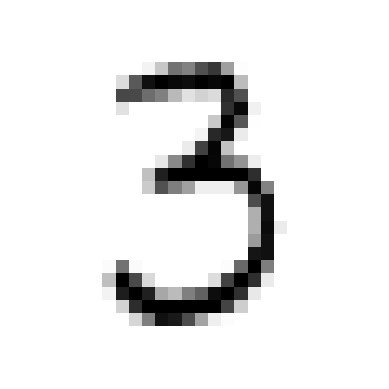

3


In [4]:
import matplotlib.pyplot as plt 

number_chosen = 50

def plot_digit(image_data):
    image = image_data.reshape(28,28)
    plt.imshow(image, cmap='binary')
    plt.axis('off')

some_digit = X[number_chosen]
plot_digit(some_digit)
plt.show()

print(y[number_chosen])

In [5]:
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

## Treinando um classificador binário

SGDClassifier https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDClassifier.html

In [6]:
y_train_5 = (y_train == '5')
y_test_5 = (y_test == '5')

In [7]:
from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(random_state=0)
sgd_clf.fit(X=X_train, y=y_train_5)

,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",0
,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if

In [8]:
sgd_clf.predict([some_digit])

array([False])

### Cálculo de performance

https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation

In [9]:
from sklearn.model_selection import cross_val_score
cross_val_score(sgd_clf, X_train, y_train_5, cv=3, scoring="accuracy")

array([0.9499, 0.9556, 0.966 ])

DummyClassifier makes predictions that ignore the input features. This classifier serves as a simple baseline to compare against other more complex classifiers.

Source: https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html

In [10]:
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier()
dummy_clf.fit(X_train, y_train_5)

# o any() verifica se pelo menos uma das chamadas é True
# Neste caso, quer dizer que nenhum 5 foi identificado no X_train
print(any(dummy_clf.predict(X_train))) 

False


In [11]:
cross_val_score(dummy_clf, X_train, y_train_5, cv=3, scoring="accuracy")

array([0.90965, 0.90965, 0.90965])

### Implementação de validação cruzada

**StratifiedKFold**

> Class-wise stratified K-Fold cross-validator. Provides train/test indices to split data in train/test sets. This cross-validation object is a variation of KFold that returns stratified folds. The folds are made by preserving the percentage of samples for each class in y in a binary or multiclass classification setting.

Source: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html



**Clone**

Clone does a deep copy of the model in an estimator without actually copying attached data. It returns a new estimator with the same parameters that has not been fitted on any data.

Source: https://scikit-learn.org/stable/modules/generated/sklearn.base.clone.html



In [12]:
# importação de bibliotecas utilizadas
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

# seleciono o método de validação cruzada
# no caso, o método de K folds extratificado
skfolds = StratifiedKFold(n_splits=3)

# cria-se 
for train_index, test_index in skfolds.split(X_train, y_train_5):
    clone_clf = clone(sgd_clf)
    X_train_folds = X_train[train_index]
    y_train_folds = y_train_5[train_index]
    
    X_test_folds = X_train[test_index]
    y_test_folds = y_train_5[test_index]

    clone_clf.fit(X_train_folds, y_train_folds)
    y_pred = clone_clf.predict(X_test_folds)

    n_correct = sum(y_pred == y_test_folds)
    accuracy = n_correct / len(y_pred)
    # print(accuracy)

## `cross_val_predit`

Retorna as predicoes feitas em cada fold de test.

Docs available on: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_predict.html



In [30]:
from sklearn.model_selection import cross_val_predict

y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_5, cv=5)

y_train_pred

array([ True, False, False, ...,  True, False, False], shape=(60000,))

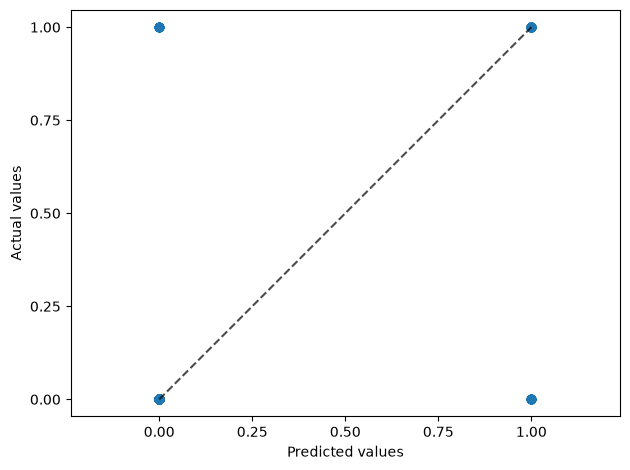

In [32]:
import matplotlib.pyplot as plt
from sklearn.metrics import PredictionErrorDisplay


PredictionErrorDisplay.from_predictions(
    y_train_5,
    y_pred=y_train_pred,
    kind="actual_vs_predicted",
    random_state=0,
)


plt.tight_layout()
plt.show()

A matriz apresenta apenas quatro tipos de valores especificos:

1. Previu 5 e eh 5;
2. Previu 5 e nao eh 5;
3. Previu nao-5 e eh 5;
4. Previu nao-5 e nao eh 5

Em suma, esta organizado assim pq eh um classificador binario

## `confusion_matrix`


Retorna matriz de confusao, dispensa comentarios

Docs: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_train_5, y_train_pred)
cm

array([[52830,  1749],
       [ 1142,  4279]])

In [ ]:
"""
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC


X, y = make_classification(random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    random_state=0)
clf = SVC(random_state=0)
clf.fit(X_train, y_train)
predictions = clf.predict(X_test)
cm = confusion_matrix(y_test, predictions, labels=clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=clf.classes_)
disp.plot()
plt.show()
"""


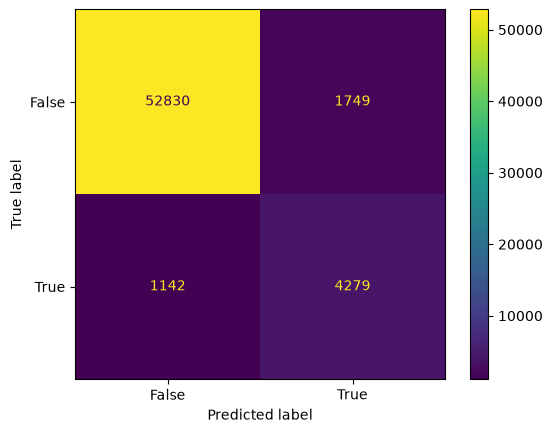

In [38]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_train_5, y_train_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=sgd_clf.classes_)
disp.plot()
plt.show()

**Medidas importantes**

1. **Precisao:** dos que o modelo chamou de 5, quantos eram 5 de verdade?

$$\text{precisao} = \frac{TP}{TP + FP}$$

onde TP Verdadeiros positivos, FP: Falsos positivos

2. **Revocacao:** dos 5 de verdade, quantos o modelo encontrou?
$$\text{revocacao} = \frac{TP}{TP + FN}$$

3. **F1-Score**? Media harmonica de precisao e revocacao.

$$F_1\text{-Score} = \frac{2}{\frac{TP}{TP + FP} + \frac{TP}{TP + FN}}$$


Docs: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_score.html

Nothing special btw

In [41]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_true=y_train_5, y_pred=y_train_pred)
recall = recall_score(y_true=y_train_5, y_pred=y_train_pred)
f1 = f1_score(y_true=y_train_5, y_pred=y_train_pred)

print(precision, recall, f1)

0.7098540145985401 0.7893377605607822 0.7474888636562145
